# Comparación ampliada: resultados CPU conservados y CUDA nueva

Sesión separada de presentación: solo lectura de mediciones y gráficas reales. Los contadores reinician en cada sesión; no se reejecuta ningún entrenamiento.

In [1]:
from pathlib import Path
import pandas as pd,json
from IPython.display import display,Image
ROOT=Path.cwd()
OUT=ROOT/'resultados/comparacion/ampliacion-fc'
comparison=pd.read_csv(OUT/'comparacion.csv')
display(comparison)
print('Speedup = media CPU / media CUDA; n=5 por modelo y dispositivo. Evaluación final sigue en CPU.')

,modelo,fase,cpu_media_s,cpu_de_s,cuda_media_s,cuda_de_s,speedup,reduccion_pct
0,CNN-B,entrenamiento_CNN-B,805.649726,2.722684,418.607683,1.916308,1.924594,48.040982
1,CNN-B,evaluacion_CNN-B,2.322390,0.071787,2.492192,0.381288,0.931866,-7.311550
2,FC-A,entrenamiento_FC-A,50.715660,1.264624,15.122541,0.332283,3.353647,70.181712
3,FC-A,evaluacion_FC-A,0.378842,0.005733,0.392414,0.004507,0.965414,-3.582510
4,FC-B,entrenamiento_FC-B,102.441082,3.275205,21.061995,0.201404,4.863788,79.439895
5,FC-B,evaluacion_FC-B,0.520067,0.011493,0.523174,0.008612,0.994060,-0.597535


Speedup = media CPU / media CUDA; n=5 por modelo y dispositivo. Evaluación final sigue en CPU.


In [2]:
display(pd.read_csv(OUT/'calidad.csv'))
display(pd.read_csv(OUT/'desglose.csv'))
display(pd.read_csv(OUT/'recursos-resumen.csv'))

,modelo,origen,n,accuracy_media_pct,accuracy_min_pct,accuracy_max_pct,loss_media
0,FC-A,CPU,5,53.065133,53.065133,53.065133,1.523044
1,FC-A,CUDA,5,51.724136,51.724136,51.724136,1.572327
2,FC-B,CPU,5,44.291186,44.291186,44.291186,1.738064
3,FC-B,CUDA,5,39.961687,39.961687,39.961687,1.759407


,modelo,pared_s,validacion_cpu_s,h2d_eventos_s,d2h_eventos_s,matematica_intervalos_stream_s,resto_host_s
0,FC-A,15.122541,3.481379,1.733154,0.185665,5.548887,4.173457
1,FC-B,21.061995,5.008333,1.863861,0.222636,9.356508,4.610657


,modelo,repeticion,muestras_training,gpu_media_pct,gpu_max_pct,vram_max_mib,cpu_media_pct
0,FC-A,1,15,31.466667,50.0,111.0,121.719527
1,FC-A,2,15,30.933333,33.0,111.0,120.477216
2,FC-A,3,15,30.266667,33.0,111.0,123.102817
3,FC-A,4,15,32.133333,33.0,111.0,122.821218
4,FC-A,5,15,31.733333,34.0,111.0,123.836661
5,FC-B,1,17,37.941176,56.0,187.0,147.502830
6,FC-B,2,16,40.812500,55.0,187.0,157.620959
7,FC-B,3,16,38.625000,52.0,187.0,146.223711
8,FC-B,4,15,43.266667,55.0,187.0,142.616530
9,FC-B,5,15,43.133333,53.0,187.0,154.109161


01_fc_tiempos


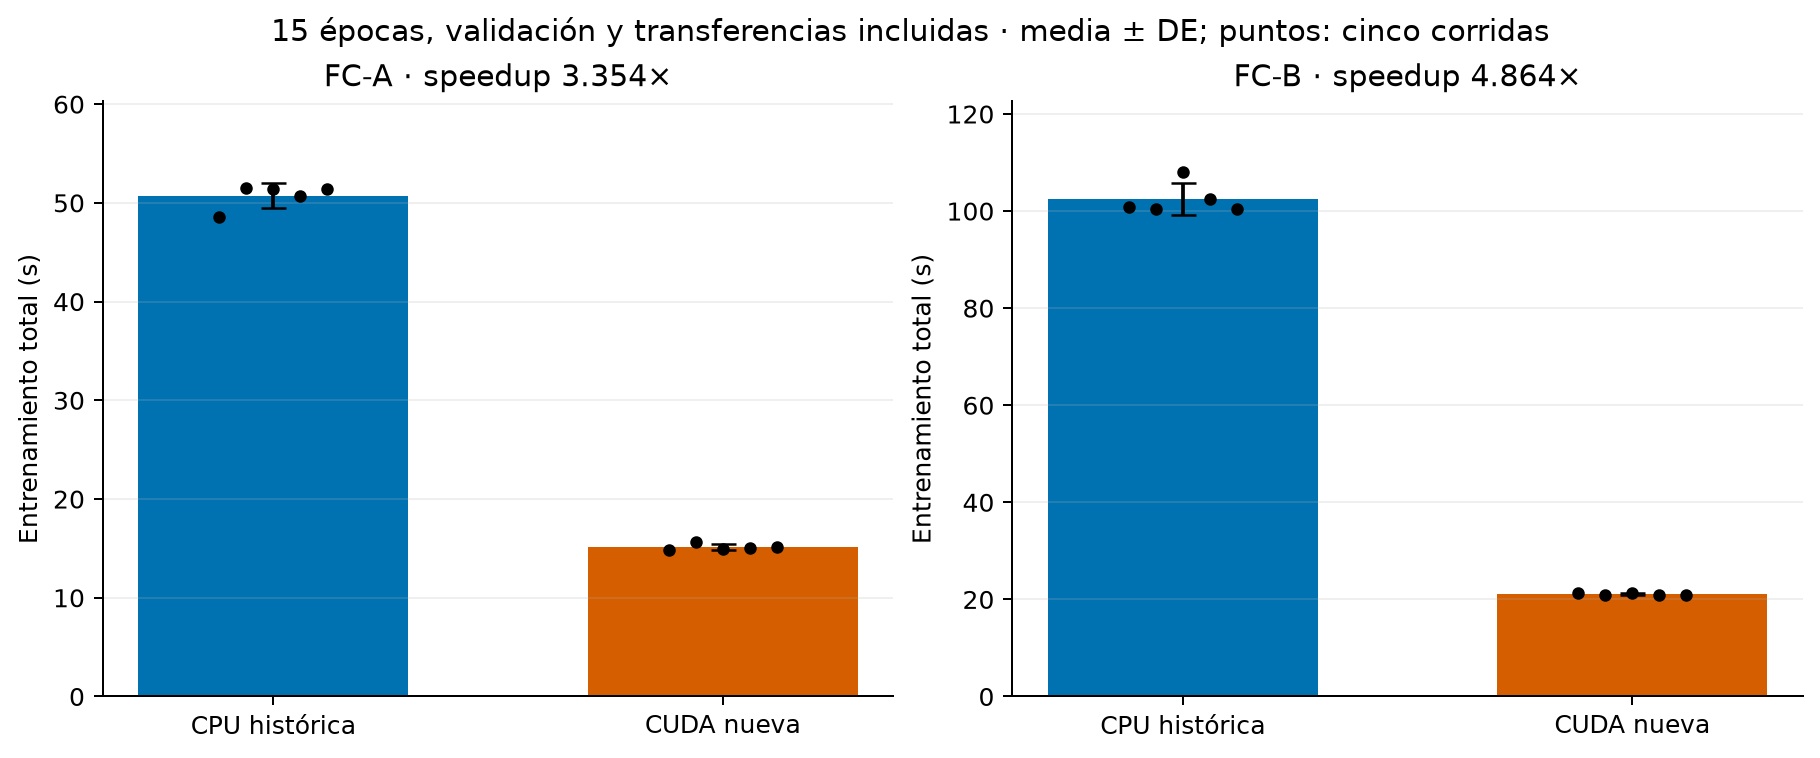

02_tres_redes_speedup


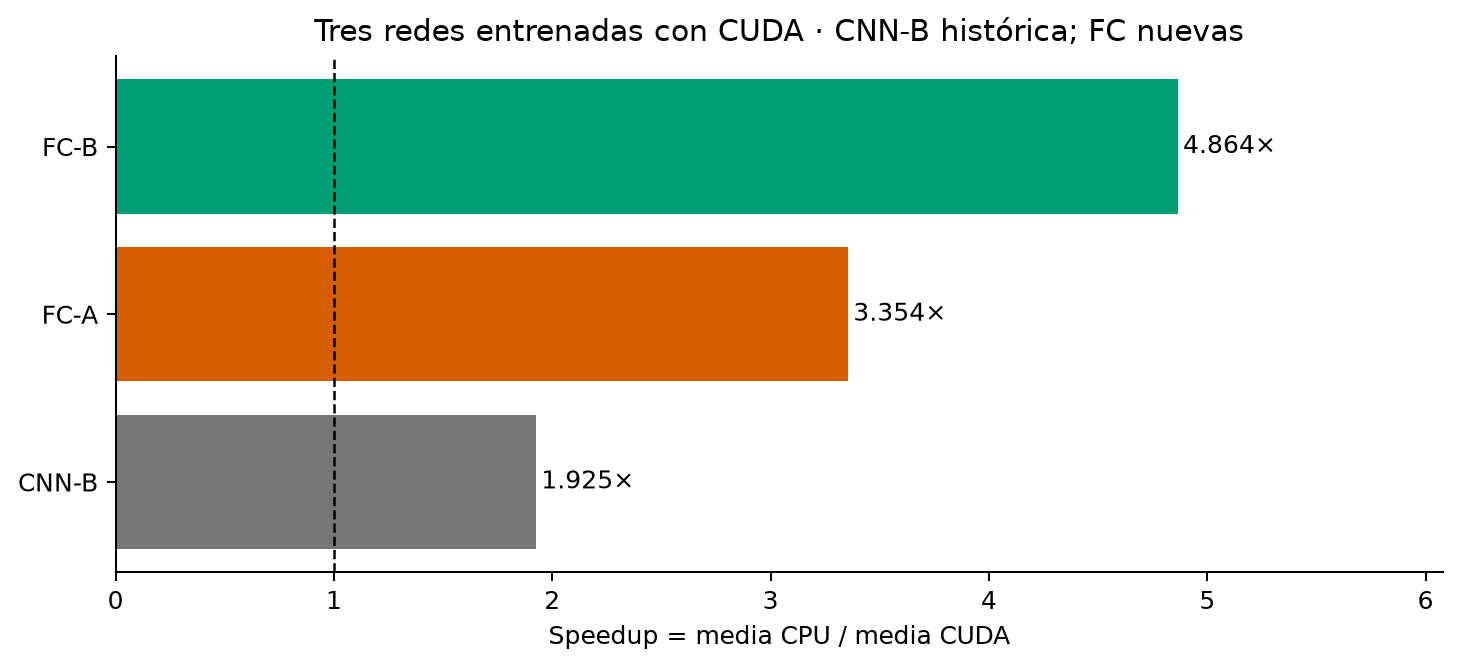

03_fc_desglose


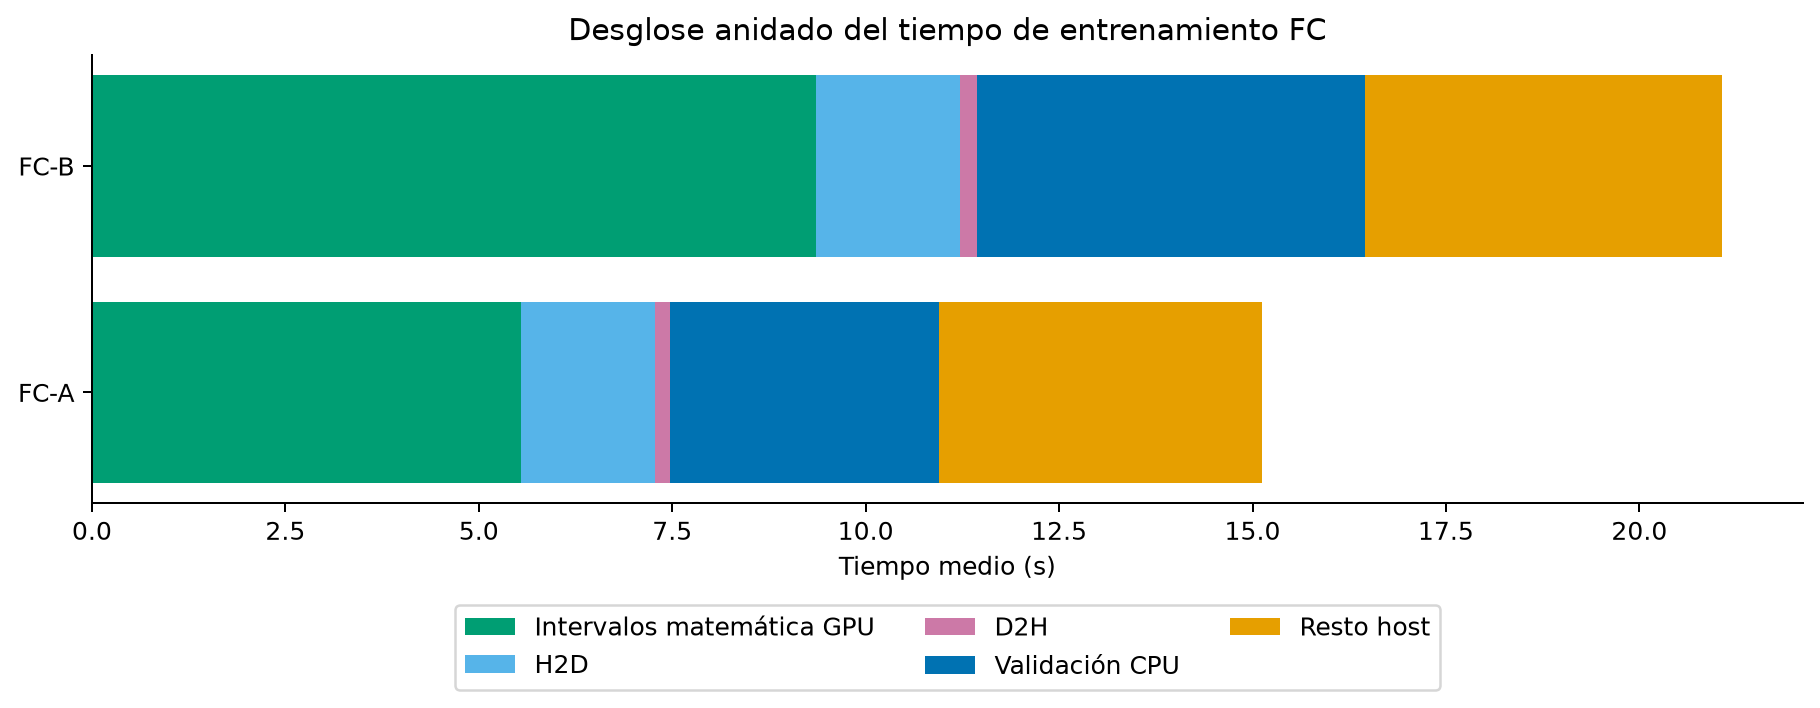

04_fc_calidad


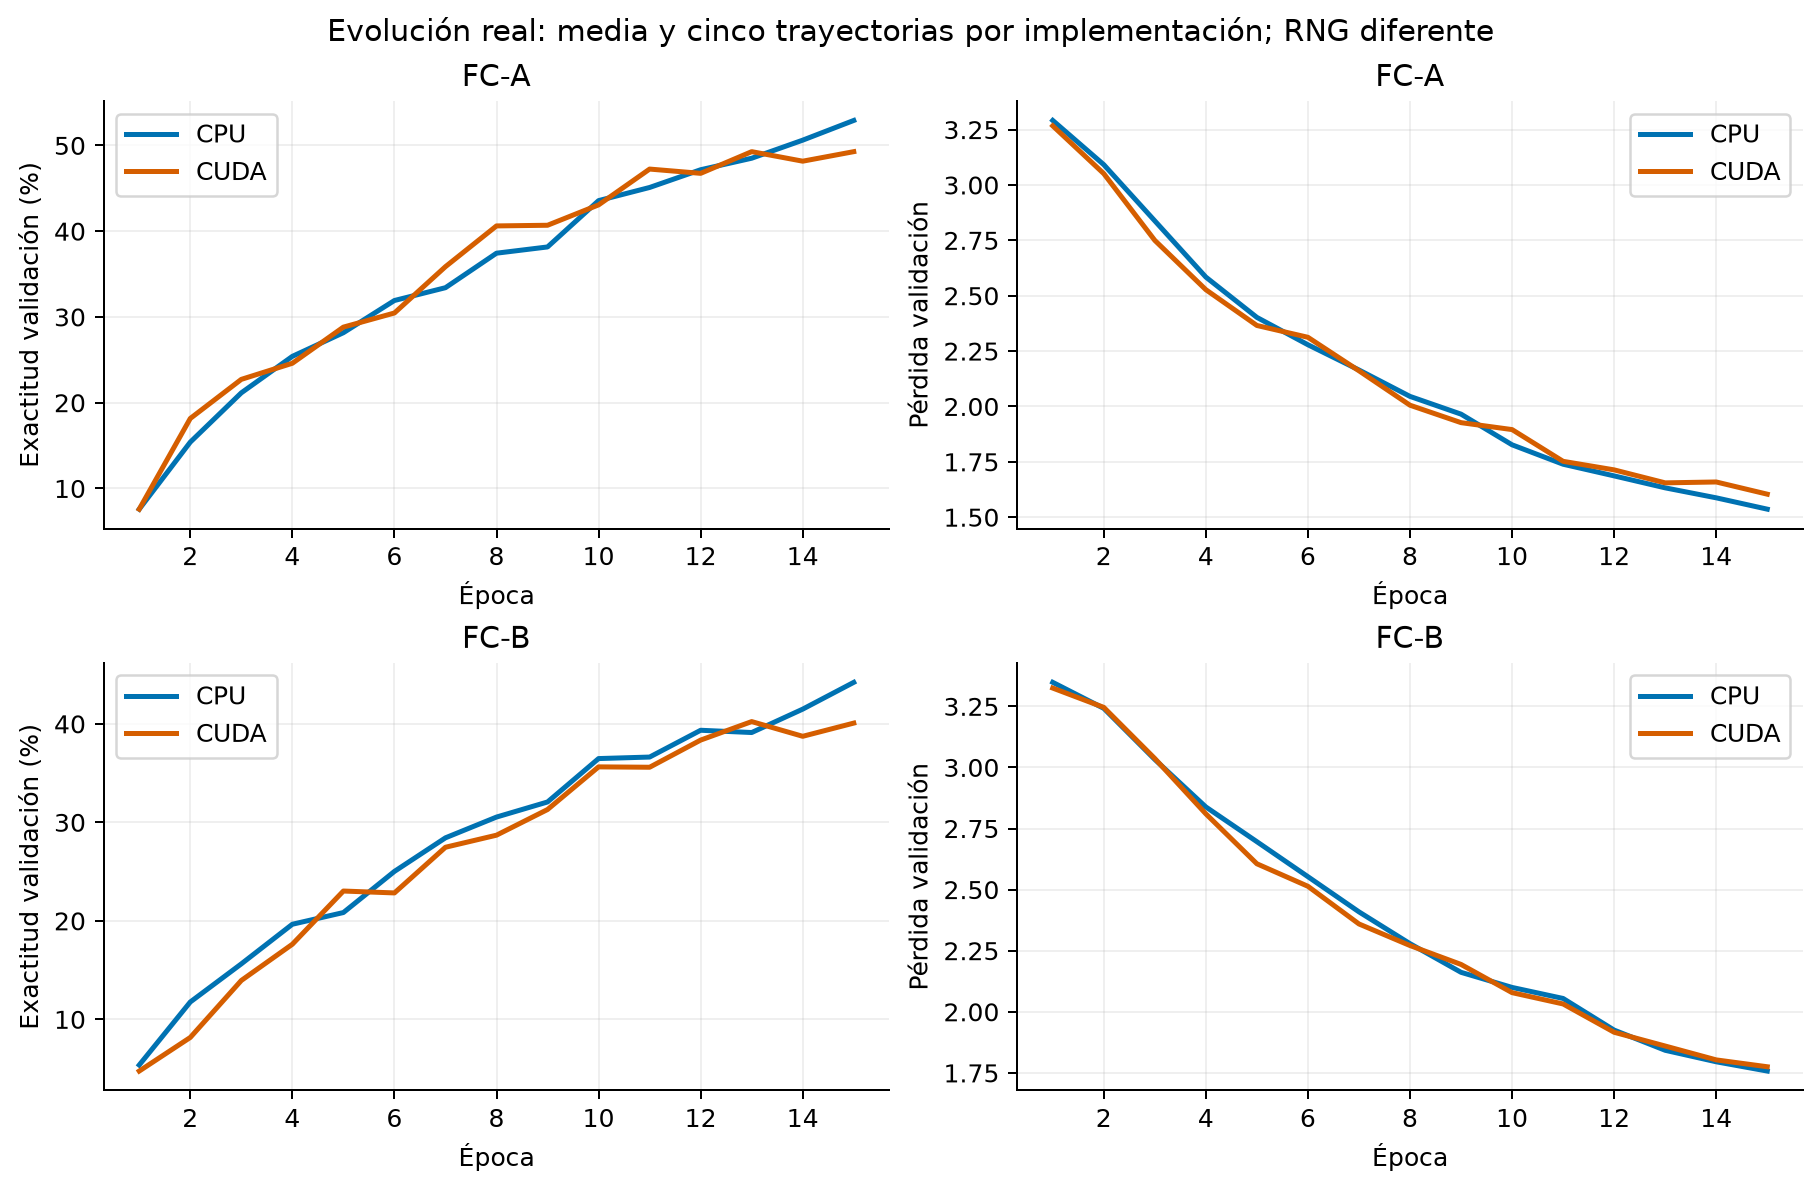

Datos idénticos por SHA-256; CPU histórica con distinto RNG interno. GPU util no equivale a ocupación por SM. Sin saturación artificial de VRAM.


In [3]:
for name in ['01_fc_tiempos','02_tres_redes_speedup','03_fc_desglose','04_fc_calidad']:
    print(name)
    display(Image(filename=str(OUT/(name+'.png'))))
print('Datos idénticos por SHA-256; CPU histórica con distinto RNG interno. GPU util no equivale a ocupación por SM. Sin saturación artificial de VRAM.')